Ячейка внизу скачивает все нужные библиотеки, запусти один раз ее и потом можешь удалять

In [ ]:
%pip install pandas numpy matplotlib seaborn plotly nltk wordcloud scikit-learn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import re
import string
import nltk
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import CountVectorizer
from nltk.corpus import stopwords
nltk.download("stopwords")


from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

[nltk_data] Downloading package stopwords to
[nltk_data]     D:\Users\artem\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [13]:
from pathlib import Path

data_path = next(
    p for p in (Path("data/bbc_news.csv"), Path("lab1_text/data/bbc_news.csv")) if p.exists()
)
df = pd.read_csv(data_path)
df.head()

,Text,Label
0,Budget to set scene for election\n \n Gordon B...,0
1,Army chiefs in regiments decision\n \n Militar...,0
2,Howard denies split over ID cards\n \n Michael...,0
3,Observers to monitor UK election\n \n Minister...,0
4,Kilroy names election seat target\n \n Ex-chat...,0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    2225 non-null   object
 1   Label   2225 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 34.9+ KB


In [15]:
df.isnull().sum()

Text     0
Label    0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(98)

In [17]:
df = df.drop_duplicates()
df.shape

(2127, 2)

Label
0    403
1    505
2    347
3    369
4    503
Name: count, dtype: int64


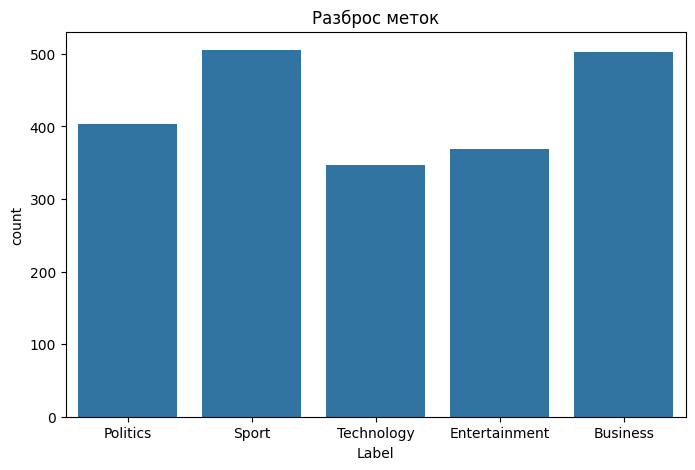

In [19]:
print(df.Label.value_counts().sort_index())
fig, ax=plt.subplots(figsize=(8,5))
sns.barplot(x=df.Label.value_counts().index, y=df.Label.value_counts(), ax=ax)
ax.set_title("Разброс меток")
ax.set_xticklabels(["Politics", "Sport", "Technology", "Entertainment", "Business"])
plt.show()

In [20]:
def clean_text(text):
    text = re.sub('\n', " ", text)
    text = re.sub(r'[^a-zA-Z]', " ", text)
    text = re.sub(r'\s+', " ", text)
    text = text.lower()
    text = text.split()
    text = [j for j in text if len(text) > 1]
    text = [i for i in text if not i in set(stopwords.words("english"))]
    text = " ".join(text)
    return text

df["cleaned_text"] = df["Text"].apply(clean_text)

In [21]:
df.head()

,Text,Label,cleaned_text
0,Budget to set scene for election\n \n Gordon B...,0,budget set scene election gordon brown seek pu...
1,Army chiefs in regiments decision\n \n Militar...,0,army chiefs regiments decision military chiefs...
2,Howard denies split over ID cards\n \n Michael...,0,howard denies split id cards michael howard de...
3,Observers to monitor UK election\n \n Minister...,0,observers monitor uk election ministers invite...
4,Kilroy names election seat target\n \n Ex-chat...,0,kilroy names election seat target ex chat show...


In [22]:
df["word_count"] = df["cleaned_text"].apply(lambda x: len(x.split()))

df["text_length"] = df["cleaned_text"].apply(lambda x: len(str(x)))

df["stopwords_count"] = df["Text"].apply(lambda x: len([i for i in x.split() if i in set(stopwords.words("english"))]))

df["punct_count"] = df["Text"].apply(lambda x: len([i for i in x if i in string.punctuation]))

df["caps_count"] = df["Text"].apply(lambda x: len([i for i in str(x) if i.isupper()]))

df.head()

,Text,Label,cleaned_text,word_count,text_length,stopwords_count,punct_count,caps_count
0,Budget to set scene for election\n \n Gordon B...,0,budget set scene election gordon brown seek pu...,308,2163,200,71,85
1,Army chiefs in regiments decision\n \n Militar...,0,army chiefs regiments decision military chiefs...,273,2078,204,54,85
2,Howard denies split over ID cards\n \n Michael...,0,howard denies split id cards michael howard de...,316,2178,201,81,99
3,Observers to monitor UK election\n \n Minister...,0,observers monitor uk election ministers invite...,291,2237,176,67,81
4,Kilroy names election seat target\n \n Ex-chat...,0,kilroy names election seat target ex chat show...,269,1833,163,88,138


In [23]:
grouped_text = df.groupby("Label").agg({"word_count": "mean",
                                        "text_length": "mean",
                                        "stopwords_count": "mean",
                                        "punct_count": "mean",
                                        "caps_count": "mean"})
grouped_text = grouped_text.reset_index(drop=True)
grouped_text

,word_count,text_length,stopwords_count,punct_count,caps_count
0,254.679901,1837.148883,178.106700,67.908189,81.114144
1,182.978218,1259.530693,127.710891,59.669307,74.093069
2,292.066282,2079.564841,198.293948,74.881844,83.034582
3,192.376694,1329.907859,118.544715,56.842818,81.696477
4,193.272366,1391.568588,117.970179,56.699801,61.242545


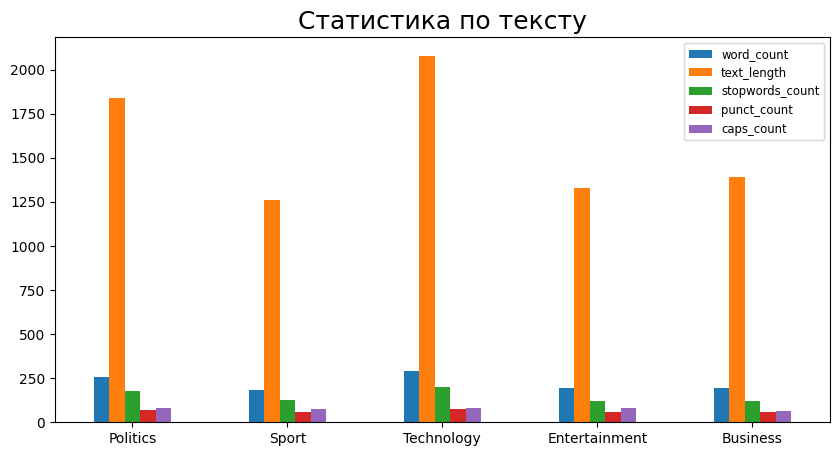

In [24]:
fig, ax=plt.subplots(figsize=(10,5))
grouped_text.plot(kind="bar", ax=ax)
ax.set_xticklabels(["Politics", "Sport", "Technology", "Entertainment", "Business"])
ax.set_title("Статистика по тексту", fontsize=18)
ax.legend(fontsize="small")
plt.xticks(rotation=0)
plt.show()

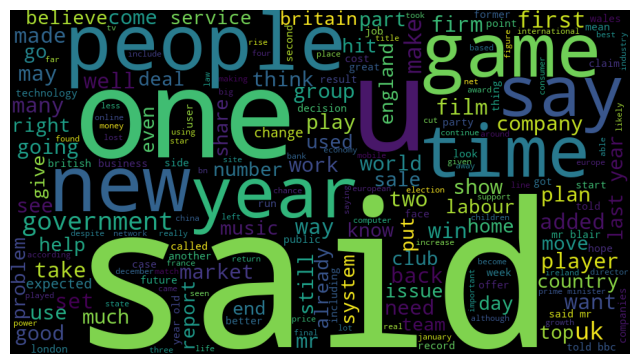

In [25]:
all_cleaned_text = " ".join(df["cleaned_text"])
word_cld = WordCloud(width=900, height=500).generate(all_cleaned_text)
plt.figure(figsize=(8,6))
plt.imshow(word_cld)
plt.axis("off")
plt.show()

In [26]:
count_vec = CountVectorizer(max_features=5000)
count_array = count_vec.fit_transform(df["cleaned_text"]).toarray()
df_count_vec = pd.DataFrame(count_array, columns=count_vec.get_feature_names_out())
df_count_vec = df_count_vec.reset_index(drop=True)
df_count_vec.head()

,aaas,abandoned,abc,ability,able,abortion,abroad,absence,absolute,absolutely,...,youngsters,youth,yuan,yugansk,yuganskneftegas,yukos,yushchenko,zealand,zero,zone
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [27]:
df1 = df.iloc[:, [1,3,4,5,6,7]]
df1 = df1.reset_index(drop=True)
df1.head()

,Label,word_count,text_length,stopwords_count,punct_count,caps_count
0,0,308,2163,200,71,85
1,0,273,2078,204,54,85
2,0,316,2178,201,81,99
3,0,291,2237,176,67,81
4,0,269,1833,163,88,138


In [28]:
df_nlp = pd.concat([df1, df_count_vec], axis=1)
df_nlp.head()

,Label,word_count,text_length,stopwords_count,punct_count,caps_count,aaas,abandoned,abc,ability,...,youngsters,youth,yuan,yugansk,yuganskneftegas,yukos,yushchenko,zealand,zero,zone
0,0,308,2163,200,71,85,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,273,2078,204,54,85,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,316,2178,201,81,99,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,291,2237,176,67,81,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,269,1833,163,88,138,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [29]:
y = df_nlp["Label"]
X = df_nlp.drop("Label", axis=1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [31]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:

# Создание и обучение наивного байесовского классификатора
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_scaled, y_train)

# Предсказание меток на тестовом наборе
y_pred_nb = nb_classifier.predict(X_test_scaled)

# Оценка точности модели
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print(f"Точность наивного байесовского классификатора: {accuracy_nb:.2f}")

# Подробный отчёт о классификации
print("Отчёт о классификации наивного байесовского классификатора:")
print(classification_report(y_test, y_pred_nb))

# Матрица ошибок
print("Матрица ошибок наивного байесовского классификатора:")
print(confusion_matrix(y_test, y_pred_nb))


Точность наивного байесовского классификатора: 0.87
Отчёт о классификации наивного байесовского классификатора:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       128
           1       0.97      0.96      0.97       161
           2       0.77      0.91      0.84        92
           3       0.89      0.84      0.86       105
           4       0.87      0.86      0.87       153

    accuracy                           0.87       639
   macro avg       0.87      0.87      0.87       639
weighted avg       0.88      0.87      0.88       639

Матрица ошибок наивного байесовского классификатора:
[[100   2   7   6  13]
 [  3 155   3   0   0]
 [  1   0  84   2   5]
 [  6   1   9  88   1]
 [ 11   1   6   3 132]]
